# Классификация риска банкротства

Логистическая регрессия с обработкой пропусков, масштабированием и балансировкой классов.

## 1. Загрузка данных

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from scipy.io import arff
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report,
                             precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
data, metadata = arff.loadarff('1year.arff')
df = pd.DataFrame(data)
df['class'] = df['class'].astype(int)
df.head()


,Attr1,Attr2,Attr3,Attr4,Attr5,Attr6,Attr7,Attr8,Attr9,Attr10,...,Attr56,Attr57,Attr58,Attr59,Attr60,Attr61,Attr62,Attr63,Attr64,class
0,0.200550,0.37951,0.39641,2.0472,32.3510,0.38825,0.249760,1.33050,1.1389,0.50494,...,0.121960,0.39718,0.87804,0.001924,8.4160,5.1372,82.658,4.4158,7.4277,0
1,0.209120,0.49988,0.47225,1.9447,14.7860,0.00000,0.258340,0.99601,1.6996,0.49788,...,0.121300,0.42002,0.85300,0.000000,4.1486,3.2732,107.350,3.4000,60.9870,0
2,0.248660,0.69592,0.26713,1.5548,-1.1523,0.00000,0.309060,0.43695,1.3090,0.30408,...,0.241140,0.81774,0.76599,0.694840,4.9909,3.9510,134.270,2.7185,5.2078,0
3,0.081483,0.30734,0.45879,2.4928,51.9520,0.14988,0.092704,1.86610,1.0571,0.57353,...,0.054015,0.14207,0.94598,0.000000,4.5746,3.6147,86.435,4.2228,5.5497,0
4,0.187320,0.61323,0.22960,1.4063,-7.3128,0.18732,0.187320,0.63070,1.1559,0.38677,...,0.134850,0.48431,0.86515,0.124440,6.3985,4.3158,127.210,2.8692,7.8980,0


## 2. Подготовка данных

In [2]:
X = df.drop(columns='class')
y = df['class']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        class_weight='balanced', penalty='l1', solver='liblinear',
        max_iter=2000, random_state=SEED
    )),
])
model.fit(X_train, y_train)
predictions = model.predict(X_test)


## 3. Оценка качества

              precision    recall  f1-score   support

  Не банкрот       0.98      0.69      0.81      1352
     Банкрот       0.08      0.70      0.15        54

    accuracy                           0.69      1406
   macro avg       0.53      0.70      0.48      1406
weighted avg       0.95      0.69      0.78      1406

Recall для класса «Банкрот»: 0.704
Precision для класса «Банкрот»: 0.083


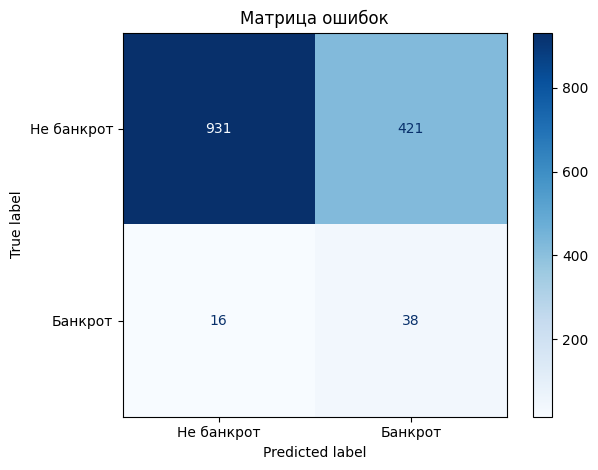

In [3]:
print(classification_report(
    y_test, predictions,
    target_names=['Не банкрот', 'Банкрот'], zero_division=0
))
print('Recall для класса «Банкрот»:', round(recall_score(y_test, predictions, pos_label=1), 3))
print('Precision для класса «Банкрот»:', round(precision_score(y_test, predictions, pos_label=1, zero_division=0), 3))

ConfusionMatrixDisplay.from_predictions(
    y_test, predictions, display_labels=['Не банкрот', 'Банкрот'], cmap='Blues'
)
plt.title('Матрица ошибок')
plt.tight_layout()
plt.show()
